In [1]:
from qiskit import QuantumCircuit, transpile
from iqm.qiskit_iqm.fake_backends.fake_garnet import IQMFakeGarnet
import matplotlib.pyplot as plt

num_qb = 11
qc = QuantumCircuit(num_qb, num_qb)

qc.x(1)
qc.barrier()
qc.measure(range(2), range(2))

backend = IQMFakeGarnet()

qc_transpiled = transpile(qc, backend)
job = backend.run(qc_transpiled, shots=1000)


res=job.result()
counts=res.get_counts()
print(qc.draw(output='text'))

            ░ ┌─┐   
 q_0: ──────░─┤M├───
      ┌───┐ ░ └╥┘┌─┐
 q_1: ┤ X ├─░──╫─┤M├
      └───┘ ░  ║ └╥┘
 q_2: ──────░──╫──╫─
            ░  ║  ║ 
 q_3: ──────░──╫──╫─
            ░  ║  ║ 
 q_4: ──────░──╫──╫─
            ░  ║  ║ 
 q_5: ──────░──╫──╫─
            ░  ║  ║ 
 q_6: ──────░──╫──╫─
            ░  ║  ║ 
 q_7: ──────░──╫──╫─
            ░  ║  ║ 
 q_8: ──────░──╫──╫─
            ░  ║  ║ 
 q_9: ──────░──╫──╫─
            ░  ║  ║ 
q_10: ──────░──╫──╫─
            ░  ║  ║ 
c: 11/═════════╩══╩═
               0  1 


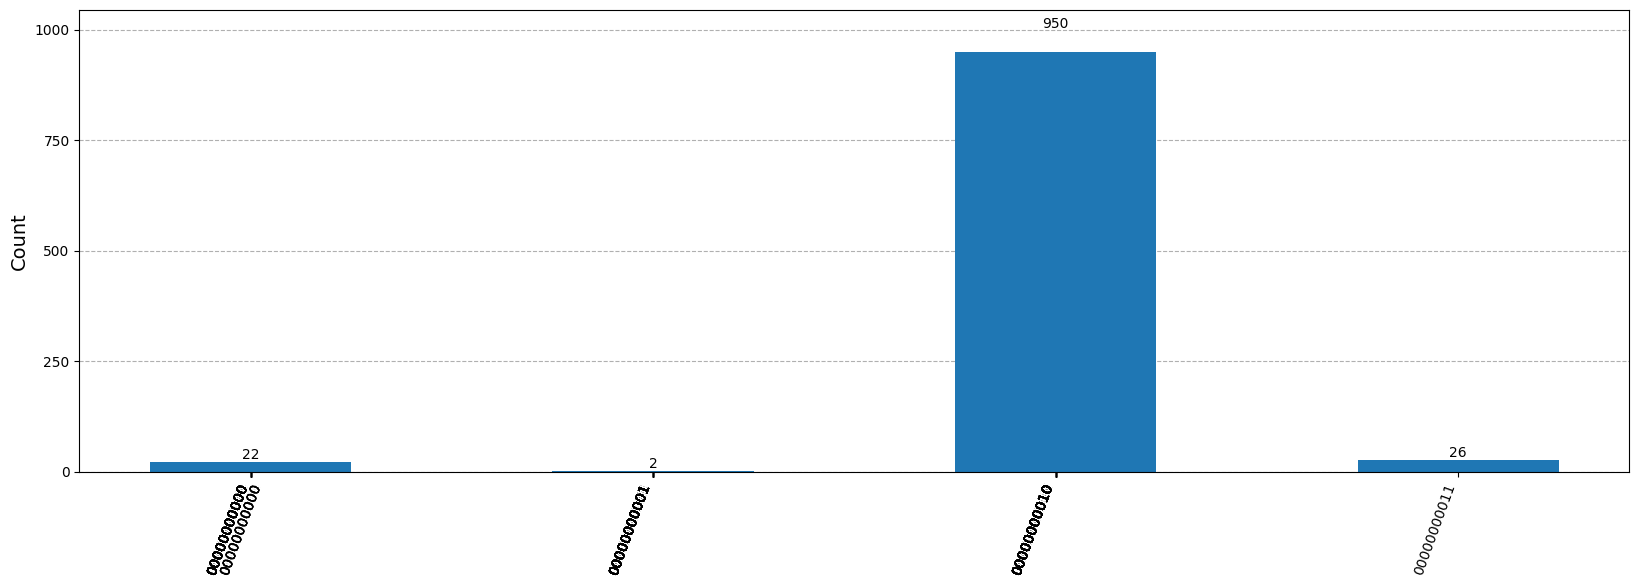

In [2]:
#Plot the results
from qiskit.visualization import plot_histogram
import numpy as np

fig, ax = plt.subplots(figsize=(20, 6))
plot_histogram(counts, ax=ax)

desired_ticks = 2**6   ### decreasing the total number of tick labels to have a clean figure
x_ticks = np.linspace(0, len(counts)-1, desired_ticks, dtype=int)
ax.set_xticks(x_ticks)

# import os
# folder_path = os.path.dirname(os.path.abspath(__file__))
# save_path = os.path.join(folder_path, "normal_circuit.png")
# plt.savefig(save_path)

plt.show()

Since qubits are initialized to |0>, and we do x on the second qubit, we expect to get |10> out, which we seem to get.